In [ ]:
import numpy as np

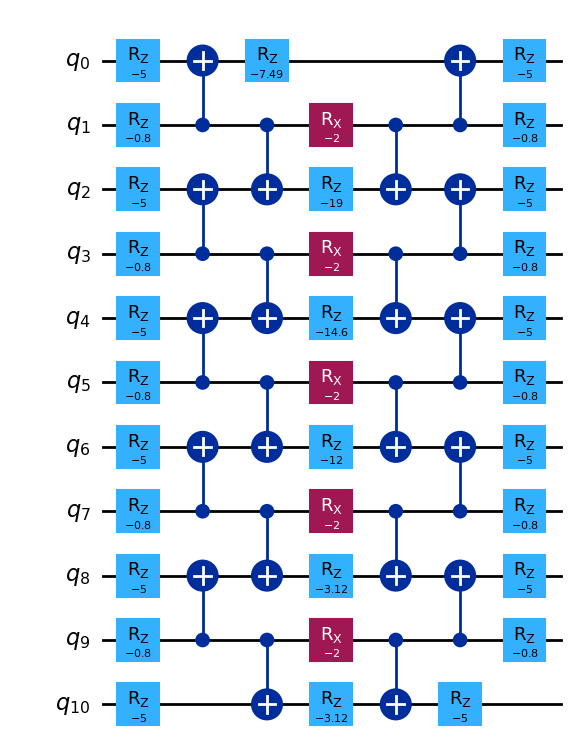

In [7]:
from z2chain.circs2 import SecondOrderTrotter
np.random.seed(42)

layer = SecondOrderTrotter(6, 5, 0.8, 1, 1, 1, 10)
layer.draw(output="mpl")

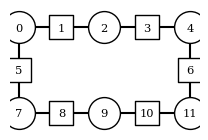

In [11]:
from z2hex.geometry import HeavyHexLattice

lattice = HeavyHexLattice(1, 1)
lattice.plot_lattice(number_qubits=True)

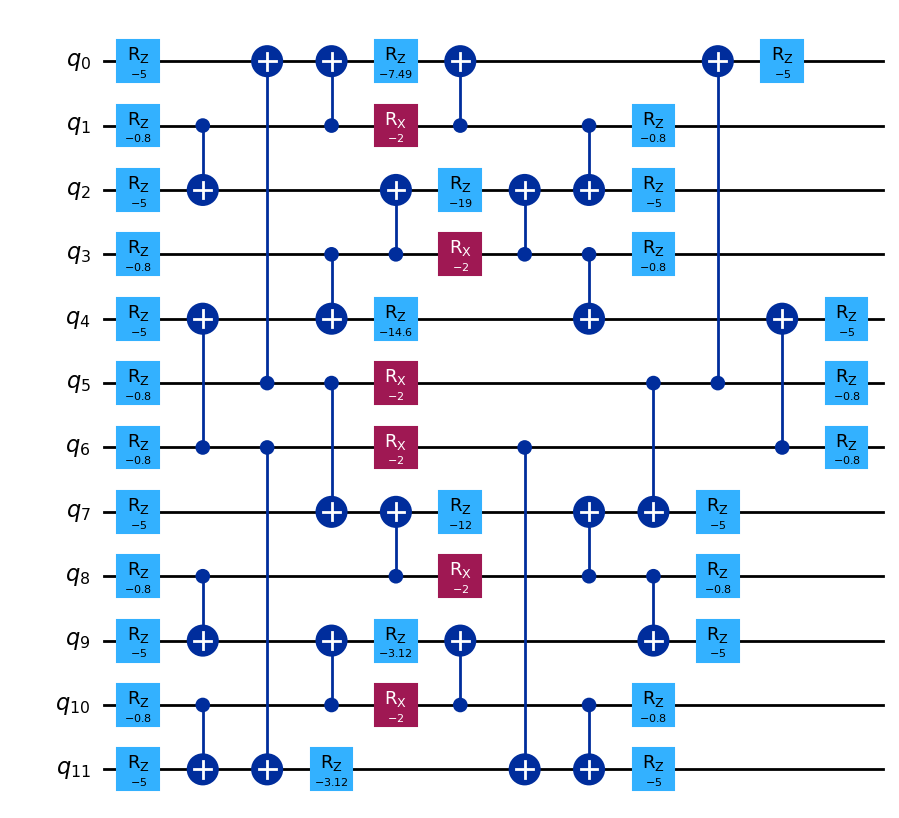

In [8]:
from z2hex.circs import SecondOrderTrotter
np.random.seed(42)

lattice = HeavyHexLattice(1, 1)

layer = SecondOrderTrotter(lattice, 5, 0.8, 1, 1, 1, 10)
layer.draw(output="mpl")

# Device selection

In [13]:
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Simulation settings

In [16]:
from utils.hexec import ExecDB

L = 21
J = 2
h = 0.8
lamb = 1
g = 10

x_basis = False

fractional_gates = False

particle_pair_left_position = L//2 - 3
particle_pair_length = 6

final_time = 5
dt = 0.15
steps = 40
desired_error = 1e-2

shots = 300000
confidence = 0.7

odr = True
flip_threshold = None

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": False,
        "enable_measure": False,
        "num_randomizations": shots//100,
        "shots_per_randomization": 100
    }
}

execution_database = "z2_chain_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

curated_data_folder_path = "Curated Data/"

# 1D

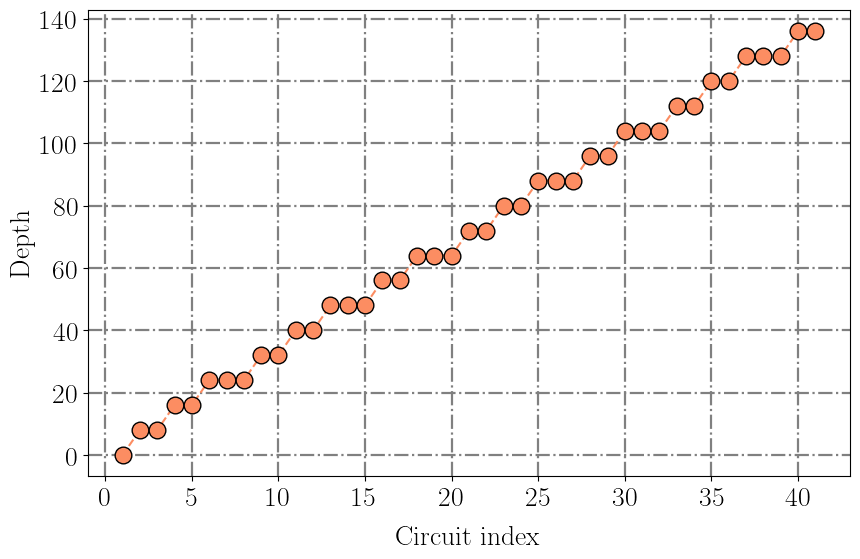



In [28]:
from z2chain.circs2 import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
import numpy as np
import os

np.random.seed(42)

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)
circs_args = (L, J, h, lamb, particle_pair_left_position, particle_pair_length, final_time, dt, steps, backend, optimization_level, g, layout, x_basis, True, False)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "L": L, "J": J, "h": h, "lamb": lamb, "g": g, "particle_pair_left_position": particle_pair_left_position, "particle_pair_length": particle_pair_length, "final_time": final_time, "dt": dt, "steps": steps}
if odr:
    odr_circ_args = (L, J, h, lamb, final_time, dt, steps, backend, g, particle_pair_left_position, particle_pair_length, layout, x_basis, False)
    odr_circuits = odr_compuncomp_circuits_dt(*odr_circ_args)
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

plot_circuit_arr_depth(circuits)

circuits[10].draw(output="mpl", idle_wires=False, filename="circs_1d.pdf")

# 2D

72 possible layouts


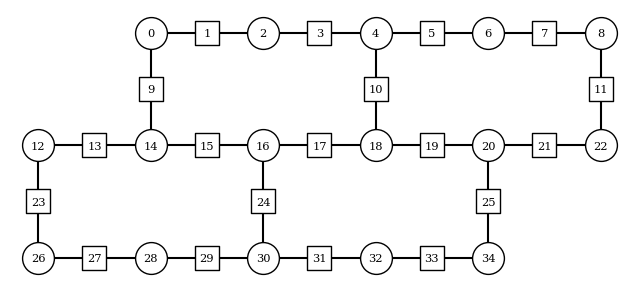

In [20]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

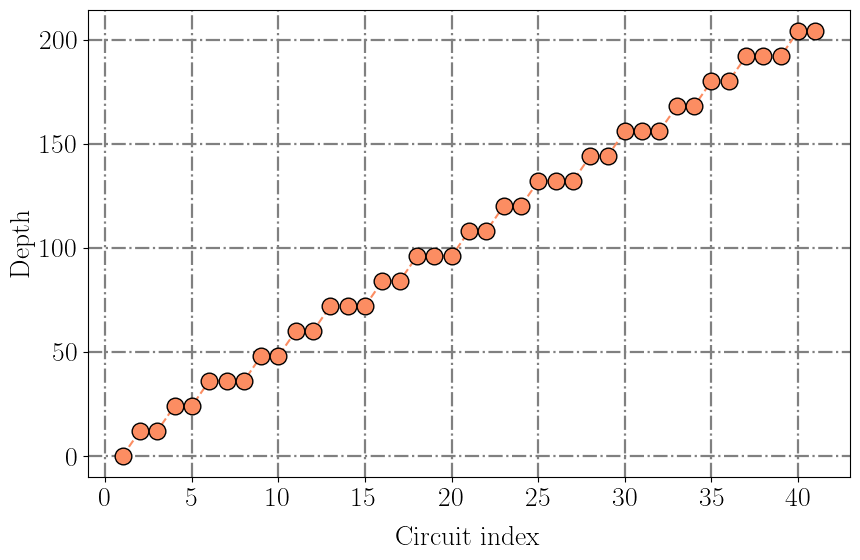



In [29]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from z2hex.geometry import HeavyHexLattice
import numpy as np
import os
np.random.seed(42)

optimization_level = 3

lattice_dims = (2, 2)
all_or_first_layout_qubit = 43
forbidden_qubits = []
max_layouts = 1

string = [4, 10, 17, 24, 30]

lattice = HeavyHexLattice(2, 2)

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]
circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g, layouts, x_basis, True, False)
# if os.path.exists(circuits_filepath):
#     circuits = load_many_layout_circs(circuits_filepath)
# else:
#     circuits = string_quench_simulation_circuits_dt(*circs_args)
    # save_many_layout_circs(circuits_filepath, circuits)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
# extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    odr_circuits_filepath = os.path.join(circ_folder_path, f"z2hex_odr_compuncomp_circs_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.qpy")
    odr_func_args = (lattice, J, h, lamb, final_time, dt, steps, backend, g, string, layouts, x_basis)
    if os.path.exists(odr_circuits_filepath):
        odr_circuits = load_many_layout_circs(odr_circuits_filepath)
    else:
        odr_circuits = odr_compuncomp_circuits_dt(*odr_func_args)
        if os.path.isdir(os.path.dirname(circuits_filepath)):
            save_many_layout_circs(odr_circuits_filepath, odr_circuits)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

plot_circuit_arr_depth(circuits[0])
circuits[0][10].draw(output="mpl", idle_wires=False)